<a href="https://colab.research.google.com/github/hithuhithesh336-star/House_Price_Prediction/blob/main/HITHESH_B(20241CSE0622).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries Imported Successfully!
Upload your train.csv.zip file


Saving train.csv.zip to train.csv (5).zip

Dataset Loaded Successfully!
Dataset Shape: (4600, 18)

First Five Rows:
                  date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  2014-05-02 00:00:00   313000.0       3.0       1.50         1340      7912   
1  2014-05-02 00:00:00  2384000.0       5.0       2.50         3650      9050   
2  2014-05-02 00:00:00   342000.0       3.0       2.00         1930     11947   
3  2014-05-02 00:00:00   420000.0       3.0       2.25         2000      8030   
4  2014-05-02 00:00:00   550000.0       4.0       2.50         1940     10500   

   floors  waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5           0     0          3        1340              0      1955   
1     2.0           0     4          5        3370            280      1921   
2     1.0           0     0          4        1930              0      1966   
3     1.0           0     0          4        1000           1000      1963   
4 

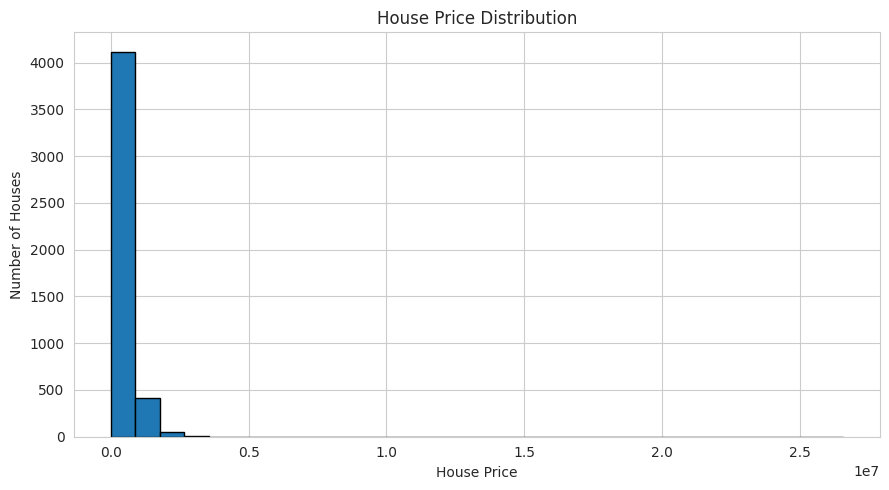

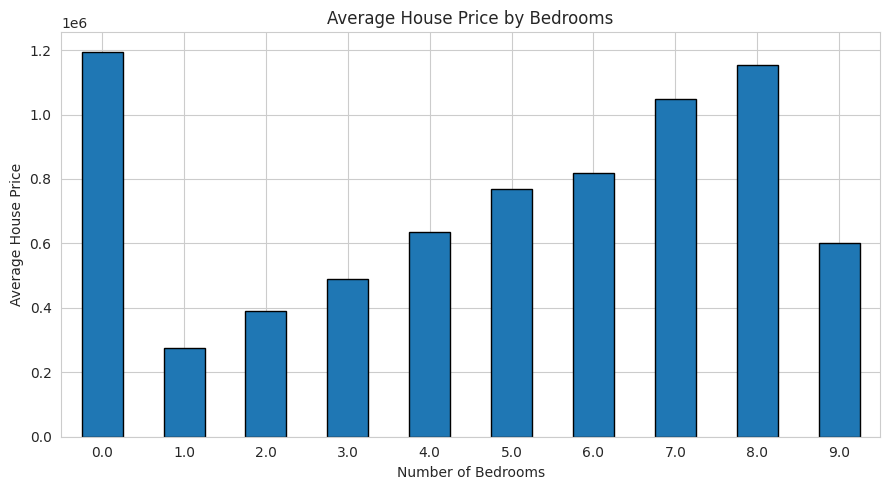

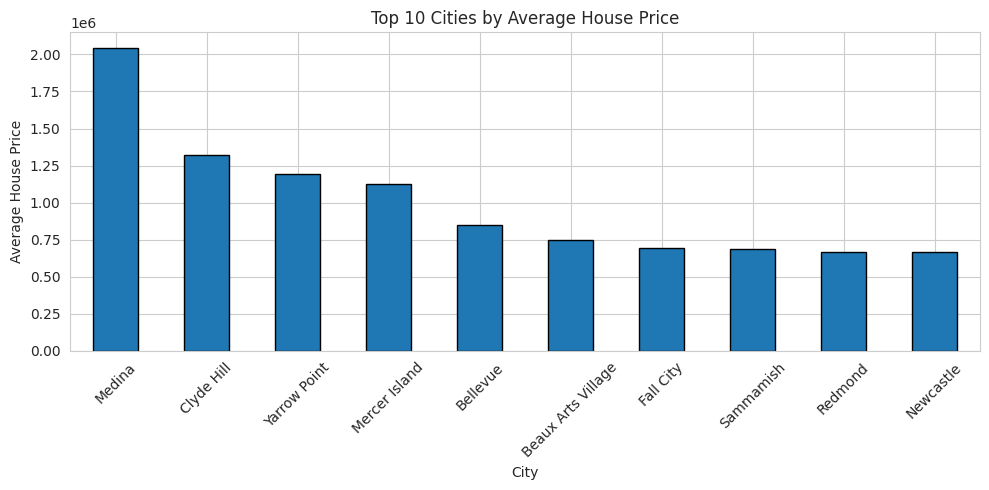

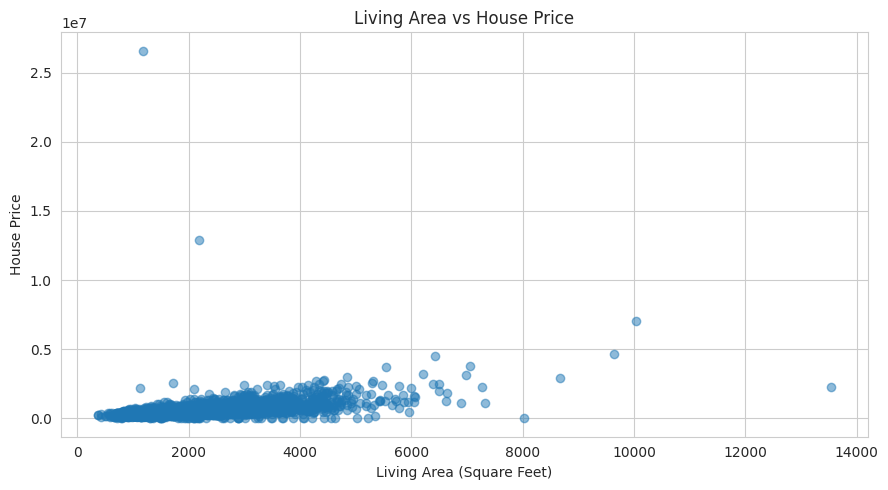

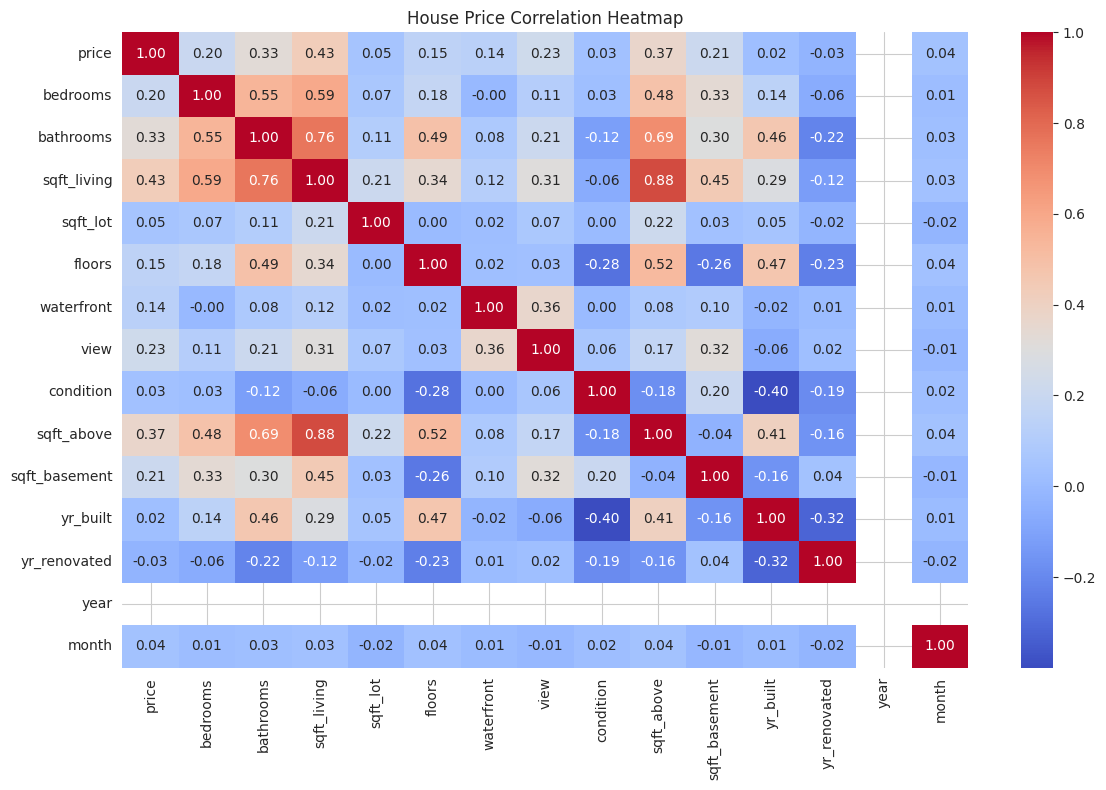


Preprocessing Completed!

Training Records: 3680
Testing Records: 920

Random Forest Model Created!

Model Training Completed!

Actual House Prices:
[ 544000.             0.       1712500.        365000.
  275000.        625000.        453000.        300000.
  417985.714286  672500.      ]

Predicted House Prices:
[ 459604.48        327915.12428571 1151842.85833333  366150.825
  252355.15047619  540642.96        620796.5         277358.6525
  612648.92        810475.5       ]

========== MODEL PERFORMANCE ==========
Mean Absolute Error: 157739.13
Mean Squared Error: 972428606682.23
Root Mean Squared Error: 986117.95
R2 Score: 0.0465
R2 Percentage: 4.65 %


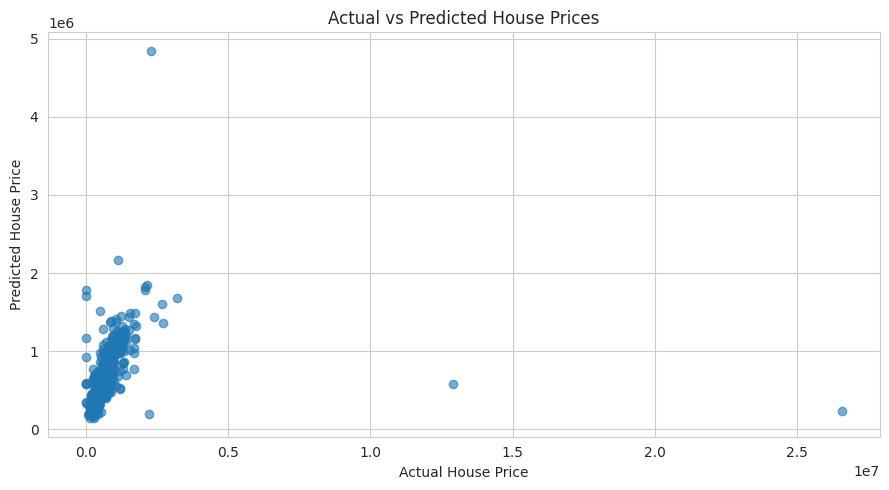

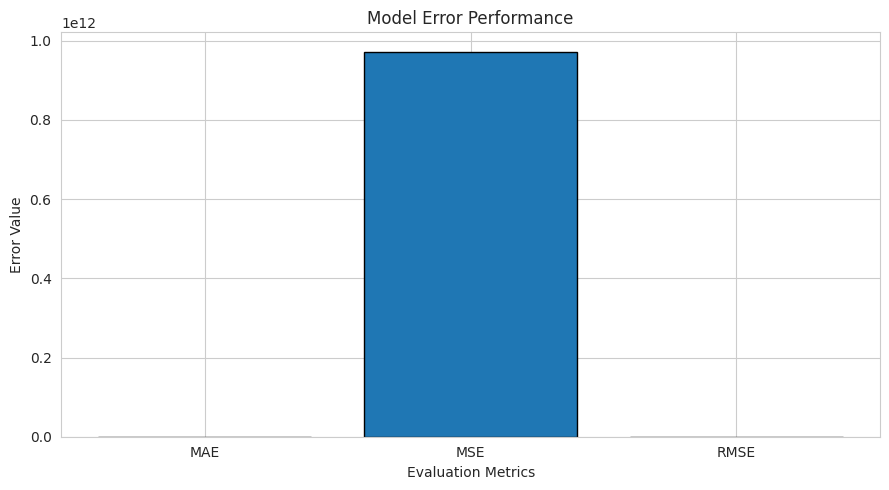

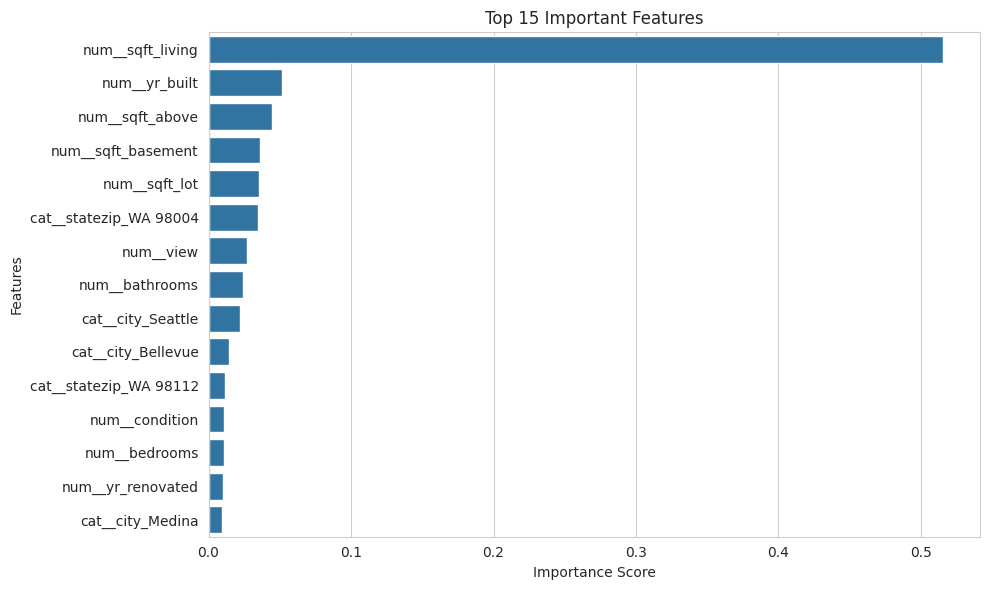


========== SAMPLE HOUSE PREDICTION ==========
Predicted Price: 459604.48
Actual Price: 544000.0

Model Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 HOUSE PRICE PREDICTION PROJECT COMPLETED
Algorithm: Random Forest Regression
Total Graphs: 8
MAE: 157739.13
RMSE: 986117.95
R2 Score: 0.0465


In [9]:

# ============================================================
# HOUSE PRICE PREDICTION USING RANDOM FOREST REGRESSION
# COMPLETE PROGRAM WITH 8 GRAPHS
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_style("whitegrid")

print("Libraries Imported Successfully!")


# 2. UPLOAD DATASET

print("Upload your train.csv.zip file")

uploaded = files.upload()

zip_name = next(
    (name for name in uploaded if name.endswith(".zip")),
    None
)

if zip_name is None:
    raise ValueError("Please upload a ZIP dataset.")

with zipfile.ZipFile(zip_name, 'r') as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith('.csv')
    ]

    if not csv_files:
        raise ValueError("No CSV file found inside ZIP.")

    selected_csv = next(
        (name for name in csv_files
         if os.path.basename(name).lower() == "data.csv"),
        csv_files[0]
    )

    with z.open(selected_csv) as f:
        df = pd.read_csv(f)

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)


# 3. DATASET INFORMATION

print("\nFirst Five Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Description:")
print(df.describe())


# 4. DATA CLEANING

df = df.drop_duplicates()

df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

df = df.drop(columns=['date', 'street', 'country'])

df = df.dropna(subset=['price'])

print("\nData Cleaning Completed!")


# 5. GRAPH 1 - HOUSE PRICE DISTRIBUTION

plt.figure(figsize=(9, 5))

plt.hist(
    df['price'],
    bins=30,
    edgecolor='black'
)

plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()


# 6. GRAPH 2 - AVERAGE PRICE BY BEDROOMS

bedroom_price = df.groupby(
    'bedrooms'
)['price'].mean()

plt.figure(figsize=(9, 5))

bedroom_price.plot(
    kind='bar',
    edgecolor='black'
)

plt.title("Average House Price by Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average House Price")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# 7. GRAPH 3 - TOP 10 CITIES BY HOUSE PRICE

city_price = df.groupby(
    'city'
)['price'].mean().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))

city_price.plot(
    kind='bar',
    edgecolor='black'
)

plt.title("Top 10 Cities by Average House Price")
plt.xlabel("City")
plt.ylabel("Average House Price")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# 8. GRAPH 4 - LIVING AREA VS HOUSE PRICE

plt.figure(figsize=(9, 5))

plt.scatter(
    df['sqft_living'],
    df['price'],
    alpha=0.5
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("House Price")

plt.tight_layout()
plt.show()


# 9. GRAPH 5 - CORRELATION HEATMAP

numeric_data = df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("House Price Correlation Heatmap")

plt.tight_layout()
plt.show()


# 10. SEPARATE INPUT AND OUTPUT

X = df.drop(columns=['price'])
y = df['price']

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()


# 11. DATA PREPROCESSING

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("\nPreprocessing Completed!")


# 12. TRAIN AND TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


# 13. RANDOM FOREST MODEL

model = Pipeline([
    ('preprocessor', preprocessor),

    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("\nRandom Forest Model Created!")


# 14. MODEL TRAINING

model.fit(X_train, y_train)

print("\nModel Training Completed!")


# 15. PREDICTION

y_pred = model.predict(X_test)

print("\nActual House Prices:")
print(y_test.head(10).values)

print("\nPredicted House Prices:")
print(y_pred[:10])


# 16. MODEL EVALUATION

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n========== MODEL PERFORMANCE ==========")

print("Mean Absolute Error:", round(mae, 2))

print("Mean Squared Error:", round(mse, 2))

print("Root Mean Squared Error:", round(rmse, 2))

print("R2 Score:", round(r2, 4))

print("R2 Percentage:", round(r2 * 100, 2), "%")


# 17. GRAPH 6 - ACTUAL VS PREDICTED

plt.figure(figsize=(9, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Actual vs Predicted House Prices")

plt.tight_layout()
plt.show()


# 18. GRAPH 7 - MODEL PERFORMANCE BAR GRAPH

plt.figure(figsize=(9, 5))

plt.bar(
    ['MAE', 'MSE', 'RMSE'],
    [mae, mse, rmse],
    edgecolor='black'
)

plt.title("Model Error Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Error Value")

plt.tight_layout()
plt.show()


# 19. GRAPH 8 - FEATURE IMPORTANCE

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = model.named_steps[
    'regressor'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


# 20. SAMPLE HOUSE PRICE PREDICTION

sample = X_test.iloc[[0]]

prediction = model.predict(sample)

print("\n========== SAMPLE HOUSE PREDICTION ==========")

print("Predicted Price:", round(prediction[0], 2))

print("Actual Price:", round(y_test.iloc[0], 2))


# 21. SAVE TRAINED MODEL

joblib.dump(
    model,
    "house_price_model.pkl"
)

print("\nModel Saved Successfully!")

files.download("house_price_model.pkl")


# ============================================================
# PROJECT COMPLETED
# ============================================================

print("\n==========================================")
print(" HOUSE PRICE PREDICTION PROJECT COMPLETED")
print("==========================================")

print("Algorithm: Random Forest Regression")

print("Total Graphs: 8")

print("MAE:", round(mae, 2))

print("RMSE:", round(rmse, 2))

print("R2 Score:", round(r2, 4))

print("==========================================")


In [10]:

# ==========================================================
# DOWNLOAD ALL VISUALIZATION GRAPHS IN ONE ZIP FILE
# ==========================================================

import os
import zipfile
from google.colab import files

# Create folder for all graphs
os.makedirs("House_Price_Visualizations", exist_ok=True)

# Save all 8 graphs separately

# GRAPH 1
plt.figure(figsize=(9, 5))
plt.hist(df['price'], bins=30, edgecolor='black')
plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_1_Price_Distribution.png")
plt.close()

# GRAPH 2
plt.figure(figsize=(9, 5))
bedroom_price.plot(kind='bar', edgecolor='black')
plt.title("Average House Price by Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_2_Bedroom_Price.png")
plt.close()

# GRAPH 3
plt.figure(figsize=(10, 5))
city_price.plot(kind='bar', edgecolor='black')
plt.title("Top 10 Cities by Average House Price")
plt.xlabel("City")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_3_City_Price.png")
plt.close()

# GRAPH 4
plt.figure(figsize=(9, 5))
plt.scatter(df['sqft_living'], df['price'], alpha=0.5)
plt.title("Living Area vs House Price")
plt.xlabel("Living Area")
plt.ylabel("House Price")
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_4_Living_Area.png")
plt.close()

# GRAPH 5
plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_5_Heatmap.png")
plt.close()

# GRAPH 6
plt.figure(figsize=(9, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_6_Actual_Predicted.png")
plt.close()

# GRAPH 7
plt.figure(figsize=(9, 5))
plt.bar(['MAE', 'MSE', 'RMSE'], [mae, mse, rmse])
plt.title("Model Error Performance")
plt.xlabel("Metrics")
plt.ylabel("Error Value")
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_7_Performance.png")
plt.close()

# GRAPH 8
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)
plt.title("Top 15 Feature Importance")
plt.tight_layout()
plt.savefig("House_Price_Visualizations/Graph_8_Feature_Importance.png")
plt.close()

# CREATE ZIP FILE
zip_name = "House_Price_All_Visualizations.zip"

with zipfile.ZipFile(zip_name, 'w') as zipf:
    for file in os.listdir("House_Price_Visualizations"):
        file_path = os.path.join(
            "House_Price_Visualizations", file
        )
        zipf.write(file_path, arcname=file)

print("All 8 Graphs Saved Successfully!")
print("ZIP File Created Successfully!")

# DOWNLOAD ZIP FILE
files.download(zip_name)

# ==========================================================
# DOWNLOAD COMPLETED
# ==========================================================


All 8 Graphs Saved Successfully!
ZIP File Created Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>